# Qiskit Fall Fest 2026
## Challenge 3: Can You Change the Correlation?

### Objective
To modify a two-qubit Bell-state circuit by adding one quantum gate, execute it for 100 shots, and compare the measurement outcomes using histograms.

### Problem Statement
Two qubits can be prepared in a state where their measurement outcomes are strongly correlated. Our task is to modify a two-qubit quantum circuit and investigate whether we can change the relationship between the two measurement outcomes.

### Proposed Modification
We will add an X gate to the second qubit of the Bell-state circuit.

### Prediction Before Execution
The original circuit is expected to produce 00 and 11 with approximately equal frequencies. After adding an X gate, the modified circuit is expected to produce 01 and 10 with approximately equal frequencies.

### Tools Used
- Python
- Qiskit
- Qiskit Aer
- Matplotlib

In [16]:
%pip install -q qiskit qiskit-aer matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Import Required Libraries

We import the required Qiskit libraries to create quantum circuits, execute them on a simulator, and visualize the measurement results.

In [18]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

## 2. Create the Original Bell-State Circuit

A Bell state is an entangled quantum state involving two qubits.

- The Hadamard (H) gate creates a superposition in the first qubit.
- The CNOT gate entangles the two qubits.
- Measurement converts the quantum states into classical outcomes.

The original circuit is expected to produce 00 and 11 with approximately equal probabilities.

Original Bell-State Circuit:


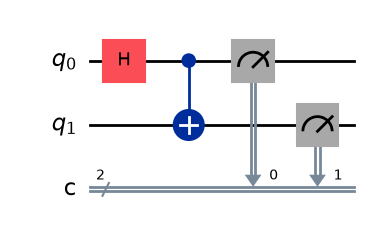

In [19]:
# Create a circuit with exactly 2 qubits and 2 classical bits
original_circuit = QuantumCircuit(2, 2)

# Apply Hadamard gate to the first qubit
original_circuit.h(0)

# Apply CNOT gate
original_circuit.cx(0, 1)

# Measure both qubits
original_circuit.measure([0, 1], [0, 1])

# Display the original circuit
print("Original Bell-State Circuit:")
display(original_circuit.draw(output="mpl"))

## 3. Prediction Before Executing the Original Circuit

We predict that both qubits will produce matching measurement outcomes.

Expected outcomes:
- 00: approximately 50%
- 11: approximately 50%
- 01: approximately 0%
- 10: approximately 0%

Since we use 100 shots, the actual counts may vary slightly due to measurement randomness.

In [20]:
# Create the quantum simulator
simulator = AerSimulator()

# Compile the original circuit
compiled_original = transpile(original_circuit, simulator)

# Execute the circuit for 100 shots
original_result = simulator.run(
    compiled_original,
    shots=100
).result()

# Get measurement counts
original_counts = original_result.get_counts()

print("Original Circuit Measurement Results:")
print(original_counts)

Original Circuit Measurement Results:
{'11': 51, '00': 49}


## 4. Original Circuit Histogram

A histogram displays how frequently each measurement outcome occurs.

We expect 00 and 11 to appear, while 01 and 10 should not appear in an ideal simulation.

In [21]:
import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

print(original_counts)

fig = plot_histogram(
    original_counts,
    title="Original Bell-State Circuit (100 Shots)"
)

plt.show()

{'11': 51, '00': 49}


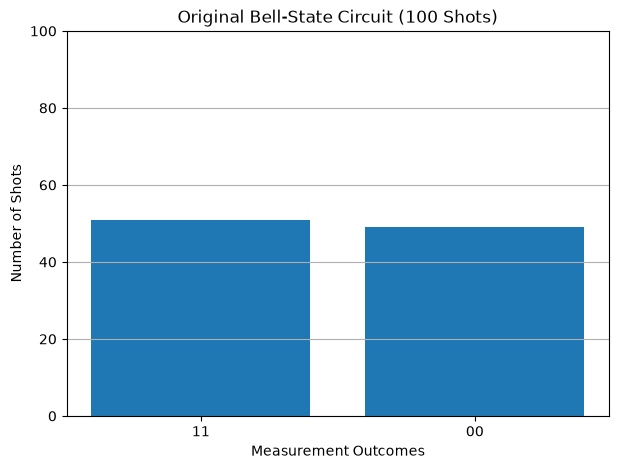

In [22]:
import matplotlib.pyplot as plt

# Measurement results
labels = list(original_counts.keys())
values = list(original_counts.values())

# Draw histogram
plt.figure(figsize=(7, 5))
plt.bar(labels, values)

plt.title("Original Bell-State Circuit (100 Shots)")
plt.xlabel("Measurement Outcomes")
plt.ylabel("Number of Shots")

plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()

## 5. Modify the Circuit Using One Quantum Gate

We add an X gate to the second qubit.

The X gate flips the qubit state:
- 0 becomes 1
- 1 becomes 0

This changes the measurement outcomes from matching outcomes to opposite outcomes.

Modified Bell-State Circuit:


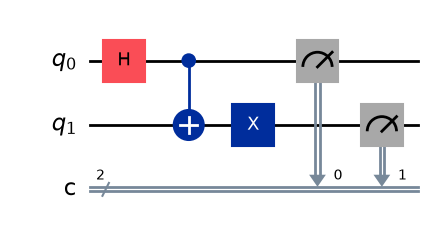

In [23]:
# Create the modified circuit
modified_circuit = QuantumCircuit(2, 2)

# Prepare the Bell state
modified_circuit.h(0)
modified_circuit.cx(0, 1)

# Add exactly one extra quantum gate
modified_circuit.x(1)

# Measure both qubits
modified_circuit.measure([0, 1], [0, 1])

# Display the modified circuit
print("Modified Bell-State Circuit:")
display(modified_circuit.draw(output="mpl"))

## 6. Prediction Before Executing the Modified Circuit

After applying the X gate to the second qubit, we expect the following outcomes:

- 00: approximately 0%
- 11: approximately 0%
- 01: approximately 50%
- 10: approximately 50%

The two qubits remain correlated, but their measurement outcomes are now opposite rather than matching.

In [24]:
# Compile the modified circuit
compiled_modified = transpile(modified_circuit, simulator)

# Execute the circuit for 100 shots
modified_result = simulator.run(
    compiled_modified,
    shots=100
).result()

# Get measurement counts
modified_counts = modified_result.get_counts()

print("Modified Circuit Measurement Results:")
print(modified_counts)

Modified Circuit Measurement Results:
{'10': 53, '01': 47}


## 7. Modified Circuit Histogram

The histogram shows the measurement outcomes after adding the X gate.

We expect 01 and 10 to appear, demonstrating that the modification has changed the relationship between the two qubits.

In [25]:
plot_histogram(
    modified_counts,
    title="Modified Bell-State Circuit (100 Shots)"
)

plt.show()

Modified Circuit Results: {'10': 53, '01': 47}


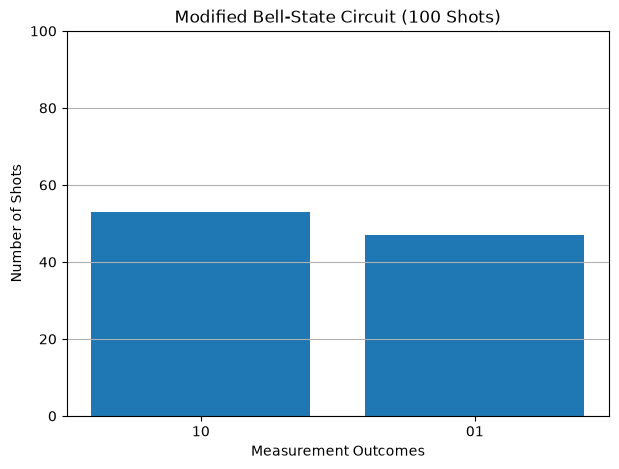

In [26]:
import matplotlib.pyplot as plt

# Modified circuit measurement results
print("Modified Circuit Results:", modified_counts)

labels = list(modified_counts.keys())
values = list(modified_counts.values())

# Draw the modified histogram
plt.figure(figsize=(7, 5))
plt.bar(labels, values)

plt.title("Modified Bell-State Circuit (100 Shots)")
plt.xlabel("Measurement Outcomes")
plt.ylabel("Number of Shots")

plt.ylim(0, 100)
plt.grid(axis="y")
plt.show()

## 8. Compare the Original and Modified Circuits

The original circuit produces matching outcomes: 00 and 11.

The modified circuit produces opposite outcomes: 01 and 10.

The X gate changes the correlation pattern without removing the entanglement.

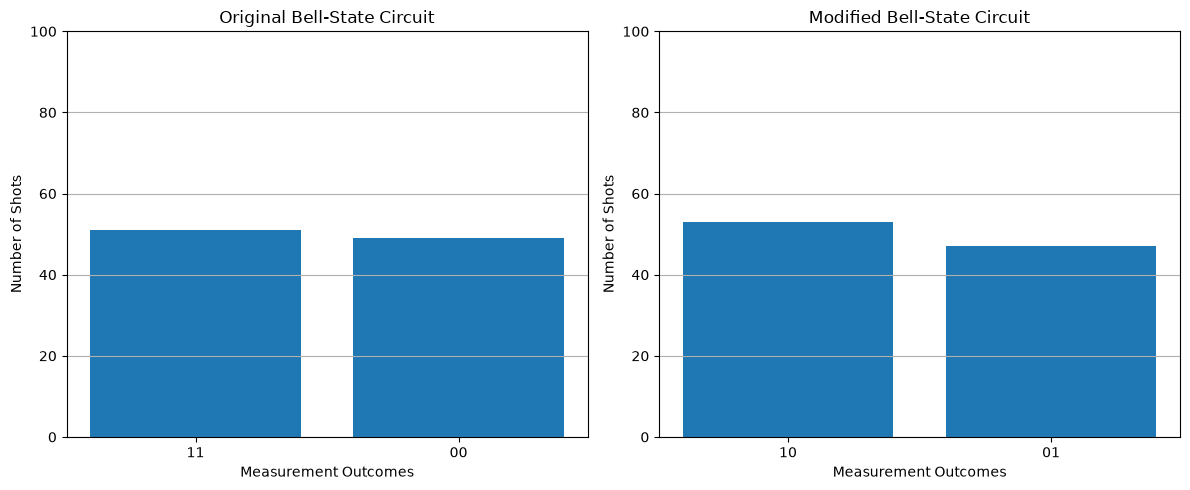

In [27]:
import matplotlib.pyplot as plt

# Create two histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Original circuit histogram
original_labels = list(original_counts.keys())
original_values = list(original_counts.values())

axes[0].bar(original_labels, original_values)
axes[0].set_title("Original Bell-State Circuit")
axes[0].set_xlabel("Measurement Outcomes")
axes[0].set_ylabel("Number of Shots")
axes[0].set_ylim(0, 100)
axes[0].grid(axis="y")

# Modified circuit histogram
modified_labels = list(modified_counts.keys())
modified_values = list(modified_counts.values())

axes[1].bar(modified_labels, modified_values)
axes[1].set_title("Modified Bell-State Circuit")
axes[1].set_xlabel("Measurement Outcomes")
axes[1].set_ylabel("Number of Shots")
axes[1].set_ylim(0, 100)
axes[1].grid(axis="y")

# Display both histograms
plt.tight_layout()
plt.show()

## 9. Measurement Results Comparison

| Measurement Outcome | Original Circuit | Modified Circuit |
|---|---|---|
| 00 | Expected | Not expected |
| 01 | Not expected | Expected |
| 10 | Not expected | Expected |
| 11 | Expected | Not expected |

The original circuit produces matching outcomes, whereas the modified circuit produces opposite outcomes.

In [28]:
# Compare the actual measurement counts
print("Original Circuit Counts:", original_counts)
print("Modified Circuit Counts:", modified_counts)

print("\nComparison:")

for outcome in ["00", "01", "10", "11"]:
    original_value = original_counts.get(outcome, 0)
    modified_value = modified_counts.get(outcome, 0)

    print(
        f"Outcome {outcome}: "
        f"Original = {original_value}, "
        f"Modified = {modified_value}"
    )

Original Circuit Counts: {'11': 51, '00': 49}
Modified Circuit Counts: {'10': 53, '01': 47}

Comparison:
Outcome 00: Original = 49, Modified = 0
Outcome 01: Original = 0, Modified = 47
Outcome 10: Original = 0, Modified = 53
Outcome 11: Original = 51, Modified = 0


## 10. Explanation of the Observed Change

The original Bell-state circuit prepares two entangled qubits. When measured, the qubits produce matching outcomes, either 00 or 11.

After adding an X gate to the second qubit, its state is flipped. Consequently, the outcomes change to 01 and 10.

Therefore, adding one quantum gate changes the measurement correlation from matching outcomes to opposite outcomes. The qubits remain entangled, but the observed correlation changes from positive to negative.

## 11. Conclusion

In this experiment, we created an original Bell-state circuit and a modified circuit using Qiskit.

Both circuits were executed for 100 shots, and their measurement results were displayed using histograms.

The original circuit produced matching measurement outcomes, while the modified circuit produced opposite outcomes after adding an X gate to the second qubit.

**Final Conclusion:** A single quantum gate can change the measurement correlation between two entangled qubits without destroying their entanglement.